## 0. Зависимости и воспроизводимость

Выбор моделей:

- `cross-encoder/mmarco-mMiniLMv2-L12-H384-v1` обучен на multilingual MS MARCO,
  использует multilingual MiniLMv2 и предназначен для reranking пар
  query–passage: https://huggingface.co/cross-encoder/mmarco-mMiniLMv2-L12-H384-v1
- `Qwen/Qwen2.5-1.5B-Instruct` помещается на Colab T4 при 4-bit загрузке,
  поддерживает русский язык и структурированный JSON-вывод:
  https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct




In [ ]:
import sys, subprocess

PACKAGES = [
    "accelerate>=1.2",
    "bitsandbytes>=0.45",
     "chonkie==1.0.10",
    "sentence-transformers>=3.4,<4",
    "transformers>=4.49,<5",
    "tokenizers>=0.21,<0.22",
    "beautifulsoup4>=4.12",
    "mwparserfromhell>=0.7",
    "datasketch>=1.6",
    "rank-bm25>=0.2.2",
    "emoji>=2.12",
    "tiktoken>=0.8",
    "pandas>=2.1",
    "matplotlib>=3.8",
    "seaborn>=0.13",
    "psutil>=5.9",
    "pymilvus[milvus-lite]>=2.6",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", *PACKAGES])



0

In [ ]:
import gc
import hashlib
import json
import math
import os
import random
import re
import shutil
import statistics
import threading
import time
import unicodedata
import warnings
from collections import Counter, defaultdict
from pathlib import Path
from urllib.parse import quote

import emoji
import matplotlib.pyplot as plt
import mwparserfromhell
import numpy as np
import pandas as pd
import psutil
import seaborn as sns
import tiktoken
import torch
from bs4 import BeautifulSoup
from datasketch import MinHash, MinHashLSH
from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers import BitsAndBytesConfig, AutoModelForCausalLM, AutoTokenizer
from chonkie import TokenChunker
from pymilvus import DataType, MilvusClient
import pymilvus


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

OUT = Path("/content/kt4_outputs") if Path("/content").exists() else Path("kt4_outputs")
OUT.mkdir(parents=True, exist_ok=True)

QUICK_MODE = False
LATENCY_REPEATS = 10 if QUICK_MODE else 100
VALIDATION_LIMIT = 8 if QUICK_MODE else None
EVAL_KS = (1, 5, 10)
RRF_K = 60

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE != "cuda":
    warnings.warn("GPU не найдена. LLM и cross-encoder будут очень медленными.")
print("Device:", DEVICE)
print("Latency repetitions:", LATENCY_REPEATS)
print("Outputs:", OUT)



Device: cuda
Latency repetitions: 100
Outputs: /content/kt4_outputs


In [ ]:
KT3_BASELINE = {
    "decision_source": "KT2 validation split only",
    "preprocessing": {
        "stage": "04_dedup",
        "unicode_normalization": "NFKC",
        "remove_markup": True,
        "remove_urls": True,
        "remove_emoji": True,
        "keep_numbers": True,
        "keep_sentence_punctuation": True,
        "deduplication": {
            "exact": True,
            "near_duplicate": True,
            "shingle_width": 5,
            "minhash_num_perm": 128,
            "jaccard_threshold": 0.88,
            "seed": 42,
        },
    },
    "chunker": {
        "name": "ParentDocumentRetriever",
        "configuration": "P2048_C512",
        "parent_size": 2048,
        "parent_overlap": 256,
        "child_size": 512,
        "child_overlap": 64,
    },
    "retriever": {
        "embedding_model": "BAAI/bge-m3",
        "indexed_objects": "child_chunks",
        "returned_objects": "parent_chunks",
        "parent_score": "max_child_score",
    },
    "metadata_prepend": False,
    "llm_processing": None,
    "kt2_validation_metrics": {
        "Hit@5": 0.818182,
        "Recall@5": 0.727273,
    },
}

BASELINE_PATH = OUT / "kt3_baseline_config.json"
if BASELINE_PATH.exists():
    saved = json.loads(BASELINE_PATH.read_text(encoding="utf-8"))
    assert saved == KT3_BASELINE, "Baseline КТ 3 изменён — верните зафиксированные параметры."
else:
    BASELINE_PATH.write_text(
        json.dumps(KT3_BASELINE, ensure_ascii=False, indent=2), encoding="utf-8"
    )

PARENT_SIZE = 2048
PARENT_OVERLAP = 256
CHILD_SIZE = 512
CHILD_OVERLAP = 64
MINHASH_THRESHOLD = 0.88
MINHASH_PERMUTATIONS = 128
SHINGLE_WIDTH = 5
EVIDENCE_COVERAGE_THRESHOLD = 0.50
BGE_MODEL_NAME = "BAAI/bge-m3"
BGE_MAX_SEQ_LENGTH = 1024
BGE_BATCH_SIZE = 8 if torch.cuda.is_available() else 2
PRIMARY_K = 5

print(json.dumps(KT3_BASELINE, ensure_ascii=False, indent=2))



{
  "decision_source": "KT2 validation split only",
  "preprocessing": {
    "stage": "04_dedup",
    "unicode_normalization": "NFKC",
    "remove_markup": true,
    "remove_urls": true,
    "remove_emoji": true,
    "keep_numbers": true,
    "keep_sentence_punctuation": true,
    "deduplication": {
      "exact": true,
      "near_duplicate": true,
      "shingle_width": 5,
      "minhash_num_perm": 128,
      "jaccard_threshold": 0.88,
      "seed": 42
    }
  },
  "chunker": {
    "name": "ParentDocumentRetriever",
    "configuration": "P2048_C512",
    "parent_size": 2048,
    "parent_overlap": 256,
    "child_size": 512,
    "child_overlap": 64
  },
  "retriever": {
    "embedding_model": "BAAI/bge-m3",
    "indexed_objects": "child_chunks",
    "returned_objects": "parent_chunks",
    "parent_score": "max_child_score"
  },
  "metadata_prepend": false,
  "llm_processing": null,
  "kt2_validation_metrics": {
    "Hit@5": 0.818182,
    "Recall@5": 0.727273
  }
}


In [ ]:
%pip -q install tiktoken datasketch scikit-learn matplotlib numpy

import hashlib
import urllib.request
import urllib.error
import shutil
from pathlib import Path

URL = 'https://dumps.wikimedia.org/ruwikivoyage/20260901/ruwikivoyage-20260901-pages-articles-multistream.xml.bz2'
DATA = Path('/content/ruwikivoyage-20260901.xml.bz2')

if not DATA.exists():
  request = urllib.request.Request(URL, headers={'User-Agent': 'RAG-course-EDA/1.0 (academic project)'})
  with urllib.request.urlopen(request, timeout=30) as response, DATA.open('wb') as out:
      shutil.copyfileobj(response, out)
  print('Архив скачан автоматически.')

Архив скачан автоматически.


In [ ]:
import bz2
import collections
import hashlib
import html
import json
import re
import sys
from functools import lru_cache
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tiktoken
from datasketch import MinHash, MinHashLSH
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

DATA = Path('/content/ruwikivoyage-20260901.xml.bz2')
OUT = Path('/content/eda_output')
OUT.mkdir(exist_ok=True)
ENC = tiktoken.get_encoding('cl100k_base')
NS = '{http://www.mediawiki.org/xml/export-0.11/}'
pages = []
with bz2.open(DATA, 'rb') as stream:
    for event, node in ET.iterparse(stream, events=('end',)):
        if node.tag != NS + 'page':
            continue
        ns = node.findtext(NS + 'ns')
        if ns == '0':
            text = node.findtext('./' + NS + 'revision/' + NS + 'text') or ''
            title = node.findtext(NS + 'title') or ''
            pages.append(dict(title=title, text=text, redirect=node.find(NS+'redirect') is not None))
        node.clear()

population_size = len(pages)
pages = sorted(pages, key=lambda p: hashlib.sha256(p['title'].encode()).digest())[:500]

for p in pages:
    p['tokens'] = len(ENC.encode(p['text'], disallowed_special=()))
counts = np.array([p['tokens'] for p in pages])
print('Parsed pages:', len(pages), 'total tokens:', int(counts.sum()), flush=True)

Parsed pages: 500 total tokens: 4562491


In [ ]:
import json

with open("/content/gold_all.json", encoding="utf-8") as f:
    CANDIDATES = json.load(f)

print(f"Восстановлено кандидатов: {len(CANDIDATES)}")

Восстановлено кандидатов: 24


In [ ]:
def sha256_text(value: str) -> str:
    return hashlib.sha256(value.encode("utf-8")).hexdigest()

docs = []
for p in pages:
    if not isinstance(p, dict) or not isinstance(p.get("title"), str) or not isinstance(p.get("text"), str):
        raise ValueError("Каждая страница корпуса должна содержать строковые title и text.")
    title = p["title"].strip()
    doc_id = str(p.get("doc_id") or sha256_text(title)[:20])
    docs.append({
        "doc_id": doc_id,
        "title": title,
        "text": p["text"],
        "url": p.get("url") or "https://ru.wikivoyage.org/wiki/" + quote(title.replace(" ", "_"), safe="/"),
        "redirect": bool(p.get("redirect", False)),
        "source": p.get("source", "ruwikivoyage"),
    })

raw_gold = [dict(x) for x in CANDIDATES]

ACCEPTED = {"accepted", "accept", "approved", "approve", "принят", "принято"}
if any("status" in x for x in raw_gold):
    gold = [x for x in raw_gold if str(x.get("status", "")).lower() in ACCEPTED]
else:
    gold = raw_gold


def maybe_json(value, default):
    if isinstance(value, str):
        try:
            return json.loads(value)
        except json.JSONDecodeError:
            return default
    return value if value is not None else default

doc_id_by_title = {d["title"]: d["doc_id"] for d in docs}
normalized_gold = []
for i, row in enumerate(gold):
    qtype = row.get("type")
    evidence = maybe_json(row.get("evidence"), [])
    if not evidence and qtype != "negative":
        ids = maybe_json(row.get("document_ids"), [])
        titles = maybe_json(row.get("document_titles"), [])
        quotes = maybe_json(row.get("quotes"), [])
        contexts = maybe_json(row.get("contexts"), [])
        urls = maybe_json(row.get("urls"), [])
        n = max(map(len, [ids, titles, quotes, contexts, urls]), default=0)
        evidence = []
        for j in range(n):
            title = titles[j] if j < len(titles) else ""
            evidence.append({
                "doc_id": ids[j] if j < len(ids) else doc_id_by_title.get(title),
                "title": title,
                "quote": quotes[j] if j < len(quotes) else "",
                "context": contexts[j] if j < len(contexts) else "",
                "url": urls[j] if j < len(urls) else "",
            })
    fixed_evidence = []
    for e in evidence:
        e = dict(e)
        if not e.get("doc_id") and e.get("title") in doc_id_by_title:
            e["doc_id"] = doc_id_by_title[e["title"]]
        fixed_evidence.append(e)
    split = str(row.get("split") or "").lower()
    if split in {"train", "val", "valid"}:
        split = "validation"
    normalized_gold.append({
        **row,
        "candidate_id": str(row.get("candidate_id") or row.get("question_id") or f"q{i:03d}"),
        "question": str(row.get("question", "")).strip(),
        "type": qtype,
        "evidence": fixed_evidence,
        "split": split,
    })
gold = normalized_gold

print("Документов:", len(docs))
display(pd.crosstab(pd.Series([x["split"] for x in gold], name="split"),
                    pd.Series([x["type"] for x in gold], name="type")))

Документов: 500


type,abstract,composite,factual,negative
split,,,,
test,2,1,2,2
validation,3,3,5,6


In [ ]:
ENCODER = tiktoken.get_encoding("gpt2")
URL_RE = re.compile(r"(?i)\b(?:https?://|www\.)\S+")
CONTENT_WORD_RE = re.compile(r"(?ui)\b[0-9a-zа-яё]{2,}\b")


def count_model_tokens(text: str) -> int:
    return len(ENCODER.encode(text, disallowed_special=()))


def remove_markup(text: str) -> str:
    text = re.sub(r"(?is)<!--.*?-->", " ", text)
    text = re.sub(r"(?is)<(?:script|style|noscript)[^>]*>.*?</(?:script|style|noscript)>", " ", text)
    text = re.sub(r"(?is)<ref\b[^>]*>.*?</ref\s*>", " ", text)
    text = re.sub(r"(?is)<ref\b[^>]*/\s*>", " ", text)
    try:
        text = mwparserfromhell.parse(text).strip_code(
            normalize=True, collapse=True, keep_template_params=True
        )
    except Exception:
        pass
    text = BeautifulSoup(text, "html.parser").get_text("\n")
    text = re.sub(r"!\[([^\]]*)\]\([^)]*\)", r"\1", text)
    text = re.sub(r"\[([^\]]+)\]\([^)]*\)", r"\1", text)
    text = re.sub(r"(?m)^\s{0,3}#{1,6}\s*", "", text)
    text = re.sub(r"(?m)^\s*>\s?", "", text)
    return text


def normalize_unicode_whitespace(text: str) -> str:
    text = unicodedata.normalize("NFKC", text)
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = text.replace("\u00a0", " ").replace("\u200b", "")
    text = re.sub(r"[\t\f\v ]+", " ", text)
    text = re.sub(r" *\n *", "\n", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


def process_symbols(text: str) -> str:
    text = URL_RE.sub(" ", text)
    text = emoji.replace_emoji(text, replace=" ")
    text = re.sub(r"[=|{}\[\]<>*_~`^]+", " ", text)
    text = "".join(
        ch if (ch in "\n\t" or unicodedata.category(ch) != "Cc") else " "
        for ch in text
    )
    return normalize_unicode_whitespace(text)


def preprocess_text(text: str) -> str:
    return process_symbols(normalize_unicode_whitespace(remove_markup(text)))


clean_docs = [{**d, "text": preprocess_text(d["text"])} for d in docs]



In [ ]:
def word_shingles(text: str, width: int = SHINGLE_WIDTH):
    words = CONTENT_WORD_RE.findall(text.lower())
    if len(words) < width:
        return {" ".join(words)} if words else {"<EMPTY>"}
    return {" ".join(words[i:i + width]) for i in range(len(words) - width + 1)}


def build_minhash(shingles):
    mh = MinHash(num_perm=MINHASH_PERMUTATIONS, seed=SEED)
    for shingle in sorted(shingles):
        mh.update(shingle.encode("utf-8"))
    return mh


def deduplicate_docs(input_docs, gold_records, threshold=MINHASH_THRESHOLD):
    refs = Counter(
        e.get("doc_id")
        for row in gold_records
        for e in row.get("evidence", [])
        if e.get("doc_id")
    )

    def choose_canonical(group):
        return max(group, key=lambda d: (refs[d["doc_id"]], len(d["text"]), d["doc_id"]))

    exact_groups = defaultdict(list)
    for d in input_docs:
        key = sha256_text(re.sub(r"\s+", " ", d["text"]).strip().lower())
        exact_groups[key].append(d)

    aliases, exact_kept = {}, []
    exact_removed = 0
    for group in exact_groups.values():
        canonical = choose_canonical(group)
        exact_kept.append(canonical)
        for d in group:
            aliases[d["doc_id"]] = canonical["doc_id"]
            exact_removed += d["doc_id"] != canonical["doc_id"]

    shingle_sets = {d["doc_id"]: word_shingles(d["text"]) for d in exact_kept}
    minhashes = {doc_id: build_minhash(sh) for doc_id, sh in shingle_sets.items()}
    lsh = MinHashLSH(threshold=threshold, num_perm=MINHASH_PERMUTATIONS)
    parent = {d["doc_id"]: d["doc_id"] for d in exact_kept}

    def root(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = root(a), root(b)
        if ra != rb:
            parent[rb] = ra

    near_pairs = []
    for d in sorted(exact_kept, key=lambda x: x["doc_id"]):
        doc_id = d["doc_id"]
        for other in lsh.query(minhashes[doc_id]):
            a, b = shingle_sets[doc_id], shingle_sets[other]
            jaccard = len(a & b) / max(1, len(a | b))
            if jaccard >= threshold:
                union(doc_id, other)
                near_pairs.append((doc_id, other, float(jaccard)))
        lsh.insert(doc_id, minhashes[doc_id])

    components = defaultdict(list)
    by_id = {d["doc_id"]: d for d in exact_kept}
    for doc_id in by_id:
        components[root(doc_id)].append(by_id[doc_id])

    final_docs, exact_to_final = [], {}
    near_removed = 0
    for group in components.values():
        canonical = choose_canonical(group)
        final_docs.append(canonical)
        for d in group:
            exact_to_final[d["doc_id"]] = canonical["doc_id"]
            near_removed += d["doc_id"] != canonical["doc_id"]

    aliases = {old: exact_to_final.get(mid, mid) for old, mid in aliases.items()}
    stats = {
        "input_documents": len(input_docs),
        "output_documents": len(final_docs),
        "exact_removed": int(exact_removed),
        "near_removed": int(near_removed),
        "removed_fraction": (exact_removed + near_removed) / max(1, len(input_docs)),
        "verified_near_pairs": len(near_pairs),
        "threshold": threshold,
        "shingle_width": SHINGLE_WIDTH,
        "num_perm": MINHASH_PERMUTATIONS,
    }
    return sorted(final_docs, key=lambda d: d["doc_id"]), aliases, stats, near_pairs


dedup_docs, duplicate_aliases, dedup_stats, near_pairs = deduplicate_docs(clean_docs, gold)
print(json.dumps(dedup_stats, ensure_ascii=False, indent=2))



{
  "input_documents": 500,
  "output_documents": 500,
  "exact_removed": 0,
  "near_removed": 0,
  "removed_fraction": 0.0,
  "verified_near_pairs": 0,
  "threshold": 0.88,
  "shingle_width": 5,
  "num_perm": 128
}


In [ ]:
def chunk_offsets(chunk, container_text, fallback_start=0):
    text = str(getattr(chunk, "text", chunk))
    start = int(getattr(chunk, "start_index", -1))
    end = int(getattr(chunk, "end_index", -1))
    if start < 0 or end < start:
        start = container_text.find(text, max(0, fallback_start))
        if start < 0:
            start = container_text.find(text)
        start = max(0, start)
        end = start + len(text)
    return text, start, end


def build_parent_child_chunks(stage_docs):
    parent_chunker = TokenChunker(
        tokenizer="gpt2", chunk_size=PARENT_SIZE,
        chunk_overlap=PARENT_OVERLAP, return_type="chunks",
    )
    child_chunker = TokenChunker(
        tokenizer="gpt2", chunk_size=CHILD_SIZE,
        chunk_overlap=CHILD_OVERLAP, return_type="chunks",
    )
    parents, children = [], []
    started = time.perf_counter()

    for doc_number, d in enumerate(stage_docs):
        if not d["text"].strip():
            continue
        parent_fallback = 0
        for parent_number, parent_part in enumerate(parent_chunker(d["text"])):
            parent_text, parent_start, parent_end = chunk_offsets(
                parent_part, d["text"], parent_fallback
            )
            parent_fallback = max(parent_start + 1, parent_end - 1)
            if not parent_text.strip():
                continue
            parent_id = sha256_text(
                f"04_dedup|P2048_C512|parent|{d['doc_id']}|{parent_number}|{parent_start}|{parent_end}"
            )[:24]
            parent_index = len(parents)
            parents.append({
                "chunk_id": parent_id,
                "parent_id": parent_id,
                "doc_id": d["doc_id"],
                "title": d["title"],
                "url": d["url"],
                "source": d["source"],
                "chunk_index": parent_number,
                "start_index": parent_start,
                "end_index": parent_end,
                "token_count": int(getattr(parent_part, "token_count", count_model_tokens(parent_text))),
                "text": parent_text,
            })

            child_fallback = 0
            for child_number, child_part in enumerate(child_chunker(parent_text)):
                child_text, local_start, local_end = chunk_offsets(
                    child_part, parent_text, child_fallback
                )
                child_fallback = max(local_start + 1, local_end - 1)
                if not child_text.strip():
                    continue
                global_start, global_end = parent_start + local_start, parent_start + local_end
                child_id = sha256_text(
                    f"{parent_id}|child|{child_number}|{global_start}|{global_end}"
                )[:24]
                children.append({
                    "chunk_id": child_id,
                    "parent_id": parent_id,
                    "parent_index": parent_index,
                    "doc_id": d["doc_id"],
                    "title": d["title"],
                    "chunk_index": child_number,
                    "start_index": global_start,
                    "end_index": global_end,
                    "token_count": int(getattr(child_part, "token_count", count_model_tokens(child_text))),
                    "text": child_text,
                })
        if (doc_number + 1) % 50 == 0:
            print(f"Чанкинг: {doc_number + 1}/{len(stage_docs)} документов")

    return parents, children, time.perf_counter() - started


parents, children, chunking_seconds = build_parent_child_chunks(dedup_docs)
parent_by_id = {p["parent_id"]: p for p in parents}

chunk_summary = pd.DataFrame([{
    "documents": len(dedup_docs),
    "parents": len(parents),
    "children": len(children),
    "mean_parent_tokens": np.mean([x["token_count"] for x in parents]),
    "median_parent_tokens": np.median([x["token_count"] for x in parents]),
    "mean_child_tokens": np.mean([x["token_count"] for x in children]),
    "median_child_tokens": np.median([x["token_count"] for x in children]),
    "chunking_seconds": chunking_seconds,
}])
display(chunk_summary.style.format({
    "mean_parent_tokens": "{:.1f}", "median_parent_tokens": "{:.1f}",
    "mean_child_tokens": "{:.1f}", "median_child_tokens": "{:.1f}",
    "chunking_seconds": "{:.1f}",
}))



/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer.json: 0.00B [00:00, ?B/s]

Чанкинг: 50/500 документов
Чанкинг: 100/500 документов
Чанкинг: 150/500 документов
Чанкинг: 200/500 документов
Чанкинг: 250/500 документов
Чанкинг: 300/500 документов
Чанкинг: 350/500 документов
Чанкинг: 400/500 документов
Чанкинг: 450/500 документов
Чанкинг: 500/500 документов


,documents,parents,children,mean_parent_tokens,median_parent_tokens,mean_child_tokens,median_child_tokens,chunking_seconds
0,500,2906,13295,1858.0,2048.0,456.1,512.0,18.2


In [ ]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE != "cuda":
    warnings.warn("GPU не найден: эмбеддинг будет значительно медленнее.")

bge_model = SentenceTransformer(BGE_MODEL_NAME, device=DEVICE)
bge_model.max_seq_length = BGE_MAX_SEQ_LENGTH


def items_signature(items):
    payload = "|".join(x["chunk_id"] for x in items)
    return sha256_text(f"{BGE_MODEL_NAME}|{BGE_MAX_SEQ_LENGTH}|{payload}")[:16]


CHILD_VECTOR_PATH = OUT / f"bge_m3_children_{items_signature(children)}.npy"
if CHILD_VECTOR_PATH.exists():
    child_vectors = np.load(CHILD_VECTOR_PATH)
    embedding_seconds = math.nan
    embeddings_from_cache = True
else:
    child_texts = [f"{x['title']}\n{x['text']}" for x in children]
    started = time.perf_counter()
    child_vectors = bge_model.encode(
        child_texts,
        batch_size=BGE_BATCH_SIZE,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    ).astype(np.float32, copy=False)
    embedding_seconds = time.perf_counter() - started
    np.save(CHILD_VECTOR_PATH, child_vectors)
    embeddings_from_cache = False

assert child_vectors.shape[0] == len(children)
assert child_vectors.dtype == np.float32

ordered_gold = sorted(gold, key=lambda x: x["candidate_id"])
question_matrix = bge_model.encode(
    [x["question"] for x in ordered_gold],
    batch_size=BGE_BATCH_SIZE,
    show_progress_bar=False,
    convert_to_numpy=True,
    normalize_embeddings=True,
).astype(np.float32, copy=False)
question_vectors = {row["candidate_id"]: question_matrix[i] for i, row in enumerate(ordered_gold)}

print("Child vectors:", child_vectors.shape)
print("Embedding seconds:", embedding_seconds, "cache:", embeddings_from_cache)



modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Batches:   0%|          | 0/1662 [00:00<?, ?it/s]

Child vectors: (13295, 1024)
Embedding seconds: 595.6393526410001 cache: False


In [ ]:
def normalize_match_text(text: str) -> str:
    return " ".join(CONTENT_WORD_RE.findall(unicodedata.normalize("NFKC", text).lower()))


def quote_coverage(quote_text: str, chunk_text: str) -> float:
    q = normalize_match_text(preprocess_text(quote_text)).split()
    c = normalize_match_text(chunk_text).split()
    if not q:
        return 0.0
    if " ".join(q) in " ".join(c):
        return 1.0
    qc, cc = Counter(q), Counter(c)
    return sum(min(n, cc[token]) for token, n in qc.items()) / len(q)


def build_parent_relevance(gold_records):
    relevance, rows = {}, []
    parents_by_doc = defaultdict(list)
    for p in parents:
        parents_by_doc[p["doc_id"]].append(p)

    for row in gold_records:
        if row["type"] == "negative":
            continue
        evidence_sets = []
        for e_idx, evidence in enumerate(row["evidence"]):
            original_doc_id = evidence["doc_id"]
            canonical_doc_id = duplicate_aliases.get(original_doc_id, original_doc_id)
            scored = []
            for p in parents_by_doc.get(canonical_doc_id, []):
                coverage = quote_coverage(evidence["quote"], p["text"])
                scored.append((p["parent_id"], coverage))
            relevant = {pid for pid, coverage in scored if coverage >= EVIDENCE_COVERAGE_THRESHOLD}
            best = max((coverage for _, coverage in scored), default=0.0)
            evidence_sets.append(relevant)
            rows.append({
                "candidate_id": row["candidate_id"],
                "evidence_index": e_idx,
                "doc_id": original_doc_id,
                "canonical_doc_id": canonical_doc_id,
                "relevant_parents": len(relevant),
                "best_parent_coverage": best,
                "aligned": bool(relevant),
            })
        relevance[row["candidate_id"]] = evidence_sets
    return relevance, pd.DataFrame(rows)


RELEVANCE, alignment_df = build_parent_relevance(gold)
if not alignment_df.empty and not alignment_df["aligned"].all():
    alignment_df = alignment_df[
        ~alignment_df["aligned"]
    ].copy()


CHILD_TO_PARENT = np.asarray([x["parent_index"] for x in children], dtype=np.int64)


def numpy_parent_search(query_vector, limit=PRIMARY_K):
    scores = child_vectors @ query_vector
    parent_scores = np.full(len(parents), -np.inf, dtype=np.float32)
    np.maximum.at(parent_scores, CHILD_TO_PARENT, scores)
    n = min(limit, len(parent_scores))
    candidate_idx = np.argpartition(-parent_scores, n - 1)[:n]
    ordered = candidate_idx[np.argsort(-parent_scores[candidate_idx], kind="stable")]
    return [parents[int(idx)]["parent_id"] for idx in ordered]


def evaluate_search(search_fn, gold_records):
    positives = [x for x in gold_records if x["type"] != "negative"]
    if not positives:
        raise ValueError("В split нет положительных вопросов.")
    per_query = []
    for row in positives:
        retrieved = set(search_fn(question_vectors[row["candidate_id"]], PRIMARY_K))
        evidence_sets = RELEVANCE[row["candidate_id"]]
        found = [bool(retrieved & relevant) for relevant in evidence_sets]
        per_query.append({
            "candidate_id": row["candidate_id"],
            "type": row["type"],
            "hit": float(any(found)),
            "recall": sum(found) / max(1, len(found)),
        })
    per_query = pd.DataFrame(per_query)
    metrics = {
        "positive_questions": len(positives),
        "Hit@5": per_query["hit"].mean(),
        "Recall@5": per_query["recall"].mean(),
    }
    by_type = per_query.groupby("type", as_index=False).agg(
        n_questions=("candidate_id", "count"),
        **{"Hit@5": ("hit", "mean"), "Recall@5": ("recall", "mean")},
    )
    return metrics, per_query, by_type


validation_gold = [x for x in gold if x["split"] == "validation"]
numpy_metrics, numpy_queries, numpy_by_type = evaluate_search(numpy_parent_search, validation_gold)
display(pd.DataFrame([{"retriever": "NumPy exact control", **numpy_metrics}]))
display(numpy_by_type)

expected = KT3_BASELINE["kt2_validation_metrics"]
for metric in ("Hit@5", "Recall@5"):
    if abs(numpy_metrics[metric] - expected[metric]) > 1e-5:
        warnings.warn(
            f"{metric}: сейчас {numpy_metrics[metric]:.6f}, в КТ 2 {expected[metric]:.6f}. "
            "Проверьте, что загружены тот же корпус и тот же gold_dataset."
        )



,retriever,positive_questions,Hit@5,Recall@5
0,NumPy exact control,11,0.818182,0.727273


,type,n_questions,Hit@5,Recall@5
0,abstract,3,0.666667,0.666667
1,composite,3,1.000000,0.666667
2,factual,5,0.800000,0.800000


In [ ]:
SELECTED_EMBEDDING_MODEL = "BAAI/bge-m3"
SELECTED_EMBEDDING_CONFIG = {
        "tier": "heavy",
        "model": "BAAI/bge-m3",
        "published_parameters_m": 567.0,
        "rumteb_avg": 61.58,
        "rumteb_retrieval": 74.79,
        "document_prefix": "",
        "query_prefix": "",
        "max_seq_length": BGE_MAX_SEQ_LENGTH,
        "batch_size_gpu": BGE_BATCH_SIZE,
        "batch_size_cpu": 2,
    }
SELECTED_INDEX_NAME = "HNSW_balanced"
SELECTED_INDEX_CONFIG = {
        "name": "HNSW_balanced",
        "index_type": "HNSW",
        "build_params": {"M": 16, "efConstruction": 128},
        "search_params": {"ef": 64},
    }
BEST_BM25_CONFIG = {
        "name": "BM25Okapi",
        "k1": 2.0,
        "b": 1.0,
    }
BEST_HYBRID_CONFIG = {
        "name": "Hybrid_weighted_alpha=0.7",
        "method": "RRF",
        "alpha": 0.6,
        "rrf_k": 60,
    }
KT3_RECOMMENDATION = {
  "selection_split": "validation",
  "rule": "max NDCG@5, then Recall@5, then MAP, then min query latency",
  "configuration": "Hybrid_weighted_alpha=0.7",
  "pipeline": "Hybrid-weighted",
  "model": "BM25 + BAAI/bge-m3",
  "index": "inverted + HNSW_balanced",
  "parameters": "minmax weighted; alpha=0.7",
  "Precision@5": 0.21818181818181825,
  "Recall@5": 0.7272727272727273,
  "NDCG@5": 0.7366827000789968,
  "MAP": 0.7152811537838276,
  "MRR": 0.8209366391184574,
  "Query_ms": 265.45248100000003,
  "reason": "Лучшее ранжирование на validation по заранее заданному правилу; test не использовался для выбора."
}



## 2. Единые метрики

Как и в КТ 3, релевантность задаётся на уровне `evidence`: один parent покрывает
evidence, если он был сопоставлен с ним при подготовке состояния. Метрики
считаются только по положительным вопросам. Для negative отдельно фиксируется
доля запросов, для которых pipeline вернул пустой список (`NegativeAccuracy`).



In [ ]:
def ranking_metrics_for_question(row, ranked_parent_ids):
    base = {
        "candidate_id": row["candidate_id"],
        "type": row["type"],
        "is_negative": row["type"] == "negative",
        "returned": len(ranked_parent_ids),
    }
    if row["type"] == "negative":
        for k in EVAL_KS:
            base[f"Precision@{k}"] = math.nan
            base[f"Recall@{k}"] = math.nan
            base[f"NDCG@{k}"] = math.nan
        base.update({"AP": math.nan, "RR": math.nan})
        return base

    evidence_sets = RELEVANCE.get(row["candidate_id"], [])
    uncovered = set(range(len(evidence_sets)))
    flags = []
    hit_count = 0
    ap_sum = 0.0
    rr = 0.0
    for rank, parent_id in enumerate(ranked_parent_ids, start=1):
        newly_covered = {i for i in uncovered if parent_id in evidence_sets[i]}
        is_new = bool(newly_covered)
        flags.append(int(is_new))
        if is_new:
            uncovered -= newly_covered
            hit_count += 1
            ap_sum += hit_count / rank
            if rr == 0.0:
                rr = 1.0 / rank

    for k in EVAL_KS:
        covered = set()
        for parent_id in ranked_parent_ids[:k]:
            covered.update(i for i, relevant in enumerate(evidence_sets) if parent_id in relevant)
        precision = sum(flags[:k]) / k
        recall = len(covered) / len(evidence_sets) if evidence_sets else 0.0
        dcg = sum(flag / math.log2(rank + 1) for rank, flag in enumerate(flags[:k], 1))
        ideal_hits = min(len(evidence_sets), k)
        idcg = sum(1.0 / math.log2(rank + 1) for rank in range(1, ideal_hits + 1))
        base[f"Precision@{k}"] = precision
        base[f"Recall@{k}"] = recall
        base[f"NDCG@{k}"] = dcg / idcg if idcg else 0.0
    base["AP"] = ap_sum / len(evidence_sets) if evidence_sets else 0.0
    base["RR"] = rr
    return base


def evaluate_rankings(configuration, rankings, records):
    rows = []
    for row in records:
        ids, _scores = rankings[row["candidate_id"]]
        rows.append(ranking_metrics_for_question(row, ids))
    per_query = pd.DataFrame(rows)
    positives = per_query[~per_query["is_negative"]]
    negatives = per_query[per_query["is_negative"]]
    metrics = {"configuration": configuration}
    for k in EVAL_KS:
        for metric in ("Precision", "Recall", "NDCG"):
            metrics[f"{metric}@{k}"] = float(positives[f"{metric}@{k}"].mean())
    metrics.update({
        "MAP": float(positives["AP"].mean()),
        "MRR": float(positives["RR"].mean()),
        "NegativeAccuracy": float((negatives["returned"] == 0).mean()) if len(negatives) else math.nan,
    })
    by_type = []
    for question_type, part in per_query.groupby("type"):
        item = {"configuration": configuration, "type": question_type, "n": len(part)}
        if question_type == "negative":
            item["NegativeAccuracy"] = float((part["returned"] == 0).mean())
        else:
            for k in EVAL_KS:
                for metric in ("Precision", "Recall", "NDCG"):
                    item[f"{metric}@{k}"] = float(part[f"{metric}@{k}"].mean())
            item["MAP"] = float(part["AP"].mean())
            item["MRR"] = float(part["RR"].mean())
        by_type.append(item)
    return metrics, per_query, pd.DataFrame(by_type)


def sync_accelerator():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def top_indices_desc(scores, limit):
    scores = np.asarray(scores)
    n = min(limit, len(scores))
    if n == 0:
        return np.array([], dtype=np.int64)
    idx = np.argpartition(-scores, n - 1)[:n]
    return idx[np.argsort(-scores[idx], kind="stable")]



## 3. Восстановление Dense, Sparse и Hybrid из КТ 3




In [ ]:
from rank_bm25 import BM25Okapi

TOKEN_RE = re.compile(r"(?u)\b\w+\b")


def sparse_tokenize(text):
    return TOKEN_RE.findall(unicodedata.normalize("NFKC", str(text)).lower())


parent_sparse_texts = [f"{x.get('title', '')}\n{x['text']}" for x in parents]
tokenized_parents = [sparse_tokenize(text) for text in parent_sparse_texts]
bm25 = BM25Okapi(
    tokenized_parents,
    k1=float(BEST_BM25_CONFIG["k1"]),
    b=float(BEST_BM25_CONFIG["b"]),
)

embedding_model = SentenceTransformer(SELECTED_EMBEDDING_MODEL, device=DEVICE)
configured_max_length = int(SELECTED_EMBEDDING_CONFIG.get("max_seq_length", 1024))
embedding_model.max_seq_length = min(
    configured_max_length,
    int(getattr(embedding_model, "max_seq_length", configured_max_length)),
)
QUERY_PREFIX = str(SELECTED_EMBEDDING_CONFIG.get("query_prefix", ""))


def encode_query(question):
    vector = embedding_model.encode(
        [QUERY_PREFIX + question],
        batch_size=1,
        show_progress_bar=False,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )[0]
    return np.asarray(vector, dtype=np.float32)


DB_PATH = OUT / "kt4_selected_index.db"
if DB_PATH.exists():
    DB_PATH.unlink()

milvus = MilvusClient(str(DB_PATH))
schema = MilvusClient.create_schema(auto_id=False, enable_dynamic_field=False)
schema.add_field("id", DataType.VARCHAR, is_primary=True, max_length=64)
schema.add_field("vector", DataType.FLOAT_VECTOR, dim=child_vectors.shape[1])
schema.add_field("parent_id", DataType.VARCHAR, max_length=64)
schema.add_field("parent_index", DataType.INT64)
schema.add_field("doc_id", DataType.VARCHAR, max_length=64)
milvus.create_collection(collection_name="rag_children", schema=schema)

INSERT_BATCH = 256
for start in range(0, len(children), INSERT_BATCH):
    data = []
    for idx in range(start, min(start + INSERT_BATCH, len(children))):
        child = children[idx]
        data.append({
            "id": child["chunk_id"],
            "vector": child_vectors[idx].tolist(),
            "parent_id": child["parent_id"],
            "parent_index": int(child["parent_index"]),
            "doc_id": child["doc_id"],
        })
    milvus.insert(collection_name="rag_children", data=data)

try:
    milvus.flush(collection_name="rag_children")
except Exception:
    pass

index_params = MilvusClient.prepare_index_params()
index_params.add_index(
    field_name="vector",
    index_name="vector_idx",
    index_type=SELECTED_INDEX_CONFIG["index_type"],
    metric_type="COSINE",
    params=SELECTED_INDEX_CONFIG["build_params"],
)
milvus.create_index(collection_name="rag_children", index_params=index_params)
milvus.load_collection(collection_name="rag_children")


def search_sparse(question, limit=100):
    scores = np.asarray(bm25.get_scores(sparse_tokenize(question)), dtype=np.float32)
    idx = top_indices_desc(scores, limit)
    return (
        [parent_ids_in_order[int(i)] for i in idx],
        [float(scores[int(i)]) for i in idx],
    )


def search_dense(question, limit=100, query_vector=None):
    if query_vector is None:
        query_vector = encode_query(question)
    result = milvus.search(
        collection_name="rag_children",
        anns_field="vector",
        data=[np.asarray(query_vector, dtype=np.float32).tolist()],
        limit=limit,
        group_by_field="parent_id",
        search_params={
            "metric_type": "COSINE",
            "params": SELECTED_INDEX_CONFIG["search_params"],
        },
        output_fields=["parent_id"],
    )
    ids, scores, seen = [], [], set()
    for hit in (result[0] if result else []):
        entity = hit.get("entity", {}) if isinstance(hit, dict) else {}
        parent_id = entity.get("parent_id") or hit.get("parent_id")
        if not parent_id or parent_id in seen:
            continue
        seen.add(parent_id)
        ids.append(parent_id)
        scores.append(float(hit.get("distance", hit.get("score", 0.0))))
    return ids, scores


def minmax_score_map(ids, scores):
    if not ids:
        return {}
    values = np.asarray(scores, dtype=np.float32)
    lo, hi = float(values.min()), float(values.max())
    normalized = np.ones_like(values) if hi - lo < 1e-12 else (values - lo) / (hi - lo)
    return {doc_id: float(score) for doc_id, score in zip(ids, normalized)}


def fuse_rrf(*ranked_results, rrf_k=RRF_K):
    fused = defaultdict(float)
    for ids, _scores in ranked_results:
        for rank, doc_id in enumerate(ids, 1):
            fused[doc_id] += 1.0 / (rrf_k + rank)
    ordered = sorted(fused.items(), key=lambda item: (-item[1], item[0]))
    return [x[0] for x in ordered], [float(x[1]) for x in ordered]


def fuse_weighted(sparse_result, dense_result, alpha):
    sparse_map = minmax_score_map(*sparse_result)
    dense_map = minmax_score_map(*dense_result)
    candidates = set(sparse_map) | set(dense_map)
    fused = {
        doc_id: alpha * dense_map.get(doc_id, 0.0) + (1 - alpha) * sparse_map.get(doc_id, 0.0)
        for doc_id in candidates
    }
    ordered = sorted(fused.items(), key=lambda item: (-item[1], item[0]))
    return [x[0] for x in ordered], [float(x[1]) for x in ordered]


def search_hybrid(question, limit=100, query_vector=None):
    sparse_result = search_sparse(question, limit)
    dense_result = search_dense(question, limit, query_vector=query_vector)
    if BEST_HYBRID_CONFIG["method"] == "RRF":
        ids, scores = fuse_rrf(
            sparse_result, dense_result,
            rrf_k=int(BEST_HYBRID_CONFIG.get("rrf_k", RRF_K)),
        )
    else:
        ids, scores = fuse_weighted(
            sparse_result, dense_result, float(BEST_HYBRID_CONFIG["alpha"])
        )
    return ids[:limit], scores[:limit]


def pipeline_family(name):
    normalized = str(name).lower()
    if normalized.startswith("hybrid"):
        return "hybrid"
    if normalized.startswith("dense"):
        return "dense"
    if normalized.startswith("sparse") or "bm25" in normalized:
        return "sparse"
    raise ValueError(f"Неизвестное семейство pipeline: {name}")


BASELINE_FAMILY = pipeline_family(KT3_RECOMMENDATION["pipeline"])


def retrieve(question, family, limit=100, query_vector=None):
    if family == "sparse":
        return search_sparse(question, limit)
    if family == "dense":
        return search_dense(question, limit, query_vector=query_vector)
    if family == "hybrid":
        return search_hybrid(question, limit, query_vector=query_vector)
    raise ValueError(family)


def retrieve_profiled(question, family, limit=100):
    timings = {"transform_ms": 0.0, "embed_ms": 0.0, "search_ms": 0.0,
               "cross_ms": 0.0, "llm_ms": 0.0}
    query_vector = None
    if family in {"dense", "hybrid"}:
        sync_accelerator()
        started = time.perf_counter_ns()
        query_vector = encode_query(question)
        sync_accelerator()
        timings["embed_ms"] = (time.perf_counter_ns() - started) / 1e6
    started = time.perf_counter_ns()
    result = retrieve(question, family, limit=limit, query_vector=query_vector)
    timings["search_ms"] = (time.perf_counter_ns() - started) / 1e6
    return result, timings



ERROR:grpc._server:Exception calling application: Method not implemented!
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/grpc/_server.py", line 608, in _call_behavior
    response_or_iterator = behavior(argument, context)
  File "/usr/local/lib/python3.13/dist-packages/pymilvus/grpc_gen/milvus_pb2_grpc.py", line 1357, in AllocTimestamp
    raise NotImplementedError('Method not implemented!')
NotImplementedError: Method not implemented!


## 4. Baseline КТ 3

Для контрольной проверки сравниваем пересчитанные метрики с карточкой КТ 3.




In [ ]:
def rankings_for_family(records, family, limit=100):
    output = {}
    for row in records:
        cached_vector = question_vectors.get(row["candidate_id"])
        output[row["candidate_id"]] = retrieve(
            row["question"], family, limit=limit, query_vector=cached_vector
        )
    return output

parent_ids_in_order = [p["parent_id"] for p in parents]
BASELINE_RANKINGS = rankings_for_family(validation_gold, BASELINE_FAMILY, limit=100)
baseline_metrics, baseline_per_query, baseline_by_type = evaluate_rankings(
    "baseline (KT3)", BASELINE_RANKINGS, validation_gold
)
display(pd.DataFrame([baseline_metrics]))
display(baseline_by_type)

for metric in ("Recall@5", "NDCG@5"):
    old = float(KT3_RECOMMENDATION[metric])
    new = float(baseline_metrics[metric])
    if abs(old - new) > 0.03:
        warnings.warn(f"{metric}: КТ3={old:.3f}, сейчас={new:.3f}. Проверьте версии и state.")



,configuration,Precision@1,Recall@1,NDCG@1,Precision@5,Recall@5,NDCG@5,Precision@10,Recall@10,NDCG@10,MAP,MRR,NegativeAccuracy
0,baseline (KT3),0.727273,0.545455,0.727273,0.181818,0.636364,0.638475,0.1,0.681818,0.658331,0.616403,0.744019,0.0


,configuration,type,n,Precision@1,Recall@1,NDCG@1,Precision@5,Recall@5,NDCG@5,Precision@10,Recall@10,NDCG@10,MAP,MRR,NegativeAccuracy
0,baseline (KT3),abstract,3,0.333333,0.166667,0.333333,0.133333,0.333333,0.306574,0.100000,0.500000,0.379376,0.338783,0.394737,NaN
1,baseline (KT3),composite,3,1.000000,0.500000,1.000000,0.266667,0.666667,0.701170,0.133333,0.666667,0.701170,0.588028,1.000000,NaN
2,baseline (KT3),factual,5,0.800000,0.800000,0.800000,0.160000,0.800000,0.800000,0.080000,0.800000,0.800000,0.800000,0.800000,NaN
3,baseline (KT3),negative,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0


/tmp/ipykernel_1533/3159244730.py:22: UserWarning: Recall@5: КТ3=0.727, сейчас=0.636. Проверьте версии и state.
  warnings.warn(f"{metric}: КТ3={old:.3f}, сейчас={new:.3f}. Проверьте версии и state.")
/tmp/ipykernel_1533/3159244730.py:22: UserWarning: NDCG@5: КТ3=0.737, сейчас=0.638. Проверьте версии и state.
  warnings.warn(f"{metric}: КТ3={old:.3f}, сейчас={new:.3f}. Проверьте версии и state.")


## 5. Multi-query expansion

Выбран этот метод, потому что Wikivoyage неоднороден: названия мест встречаются
в разных падежах и вариантах записи, а шаблонная лексика смешана с обычным
текстом. Три перефразировки повышают шанс совпасть и с лексическим BM25, и с
dense-представлением. HyDE в таком корпусе рискованнее: гипотетический ответ
может добавить отсутствующий адрес/цену. Step-back полезен для абстрактных
вопросов, но способен потерять конкретное имя собственное.

Исходный запрос и 3 перефразировки ищутся независимо, затем объединяются RRF.



In [ ]:
GENERATOR_MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

if DEVICE == "cuda":
    quantization_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
    )
    generator_model = AutoModelForCausalLM.from_pretrained(
        GENERATOR_MODEL_NAME,
        device_map="auto",
        quantization_config=quantization_config,
        torch_dtype=torch.float16,
    )
else:
    generator_model = AutoModelForCausalLM.from_pretrained(
        GENERATOR_MODEL_NAME, device_map="cpu", torch_dtype=torch.float32
    )
generator_tokenizer = AutoTokenizer.from_pretrained(GENERATOR_MODEL_NAME)
generator_model.eval()


def chat_generate(system_prompt, user_prompt, max_new_tokens=160):
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt},
    ]
    rendered = generator_tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = generator_tokenizer([rendered], return_tensors="pt").to(generator_model.device)
    input_tokens = int(inputs["input_ids"].shape[1])
    sync_accelerator()
    started = time.perf_counter_ns()
    with torch.inference_mode():
        generated = generator_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=generator_tokenizer.eos_token_id,
        )
    sync_accelerator()
    elapsed_ms = (time.perf_counter_ns() - started) / 1e6
    new_tokens = generated[0, input_tokens:]
    output_tokens = int(new_tokens.shape[0])
    text = generator_tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
    return text, {"input_tokens": input_tokens, "output_tokens": output_tokens,
                  "latency_ms": elapsed_ms}


def extract_json_array(text):
    match = re.search(r"\[[\s\S]*?\]", text)
    if not match:
        return None
    try:
        value = json.loads(match.group(0))
        return value if isinstance(value, list) else None
    except json.JSONDecodeError:
        return None


MULTI_QUERY_SYSTEM = (
    "Ты создаёшь поисковые запросы для русскоязычного корпуса Wikivoyage. "
    "Не отвечай на вопрос и не добавляй факты. Верни только JSON-массив строк."
)
MULTI_QUERY_TEMPLATE = """Создай ровно 3 разные поисковые перефразировки.
Сохрани все имена собственные, числа и ограничения исходного вопроса.
Используй разные полезные формулировки: разговорную, формальную и синонимическую.
Не исправляй намеренно редкие географические названия и не пиши ответ.

Исходный вопрос: {question}

Формат: ["запрос 1", "запрос 2", "запрос 3"]"""

MULTI_QUERY_CACHE_PATH = OUT / "multi_query_cache.json"
if MULTI_QUERY_CACHE_PATH.exists():
    MULTI_QUERY_CACHE = json.loads(MULTI_QUERY_CACHE_PATH.read_text(encoding="utf-8"))
else:
    MULTI_QUERY_CACHE = {}


def generate_multi_queries(question, use_cache=True):
    if use_cache and question in MULTI_QUERY_CACHE:
        item = MULTI_QUERY_CACHE[question]
        return item["queries"], item["usage"]
    raw, usage = chat_generate(
        MULTI_QUERY_SYSTEM,
        MULTI_QUERY_TEMPLATE.format(question=question),
        max_new_tokens=140,
    )
    parsed = extract_json_array(raw) or []
    queries = []
    for value in parsed:
        value = str(value).strip()
        if value and value.lower() != question.lower() and value not in queries:
            queries.append(value)
    if len(queries) < 3:
        # Fallback сохраняет выполнение, но помечается для ручной проверки.
        fallback = [
            f"Сведения по запросу: {question}",
            f"Практическая информация: {question}",
            f"Подробности и описание: {question}",
        ]
        for value in fallback:
            if value not in queries:
                queries.append(value)
            if len(queries) == 3:
                break
        usage["fallback_used"] = True
        usage["raw_output"] = raw
    else:
        usage["fallback_used"] = False
    queries = queries[:3]
    if use_cache:
        MULTI_QUERY_CACHE[question] = {"queries": queries, "usage": usage}
        MULTI_QUERY_CACHE_PATH.write_text(
            json.dumps(MULTI_QUERY_CACHE, ensure_ascii=False, indent=2), encoding="utf-8"
        )
    return queries, usage


def multi_query_retrieve(question, family, limit=100, use_cache=True):
    expansions, usage = generate_multi_queries(question, use_cache=use_cache)
    ranked_lists = [retrieve(question, family, limit=limit)]
    ranked_lists.extend(retrieve(q, family, limit=limit) for q in expansions)
    ids, scores = fuse_rrf(*ranked_lists, rrf_k=RRF_K)
    return (ids[:limit], scores[:limit]), expansions, usage


MULTI_QUERY_RANKINGS = {}
multi_query_usage_rows = []
for i, row in enumerate(validation_gold, 1):
    result, expansions, usage = multi_query_retrieve(
        row["question"], BASELINE_FAMILY, limit=100, use_cache=True
    )
    MULTI_QUERY_RANKINGS[row["candidate_id"]] = result
    multi_query_usage_rows.append({
        "candidate_id": row["candidate_id"], "type": row["type"],
        "question": row["question"], "expansions": json.dumps(expansions, ensure_ascii=False),
        **usage,
    })
    print(f"Multi-query: {i}/{len(validation_gold)}", end="\r")
print()

multi_metrics, multi_per_query, multi_by_type = evaluate_rankings(
    "+ multi-query", MULTI_QUERY_RANKINGS, validation_gold
)
multi_usage_df = pd.DataFrame(multi_query_usage_rows)
multi_usage_df.to_csv(OUT / "multi_query_generations.csv", index=False)

transform_comparison = pd.DataFrame([baseline_metrics, multi_metrics])
display(transform_comparison[["configuration", "Precision@5", "Recall@5", "NDCG@5", "MAP", "MRR"]])

type_delta = baseline_by_type.merge(
    multi_by_type, on="type", suffixes=("_baseline", "_multi")
)
for metric in ("Recall@5", "NDCG@5"):
    type_delta[f"delta_{metric}"] = type_delta[f"{metric}_multi"] - type_delta[f"{metric}_baseline"]
display(type_delta[["type", "n_baseline", "delta_Recall@5", "delta_NDCG@5"]])



tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Multi-query: 17/17


,configuration,Precision@5,Recall@5,NDCG@5,MAP,MRR
0,baseline (KT3),0.181818,0.636364,0.638475,0.616403,0.744019
1,+ multi-query,0.181818,0.636364,0.645774,0.614162,0.774218


,type,n_baseline,delta_Recall@5,delta_NDCG@5
0,abstract,3,0.0,0.02676
1,composite,3,0.0,0.00000
2,factual,5,0.0,0.00000
3,negative,6,NaN,NaN


## 6. Cross-encoder reranking

Проверяются candidate pool 20/50/100 и два источника кандидатов: Dense и
Hybrid. `candidate_recall` — верхняя граница: доля evidence, которая вообще
попала в пул до реранкинга. Порог выбирается отдельно для каждой конфигурации
только на validation по F1@5, затем конфигурации сравниваются по NDCG@5.



config.json:   0%|          | 0.00/891 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/471M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/435 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

cross|dense|pool=20
cross|dense|pool=50
cross|dense|pool=100
cross|hybrid|pool=20
cross|hybrid|pool=50
cross|hybrid|pool=100


,configuration,source,pool_size,candidate_recall,threshold,Precision@5,Recall@5,NDCG@5,cross_median_ms,cross_p95_ms
0,cross|dense|pool=20,dense,20,0.727273,0.257614,0.163636,0.590909,0.593897,242.980841,274.718512
1,cross|hybrid|pool=50,hybrid,50,0.727273,0.321436,0.163636,0.590909,0.593897,666.165691,686.676902
2,cross|dense|pool=50,dense,50,0.818182,0.199977,0.163636,0.590909,0.587590,610.419714,625.191225
3,cross|hybrid|pool=100,hybrid,100,0.818182,-0.034529,0.163636,0.590909,0.587590,1211.713204,1225.183242
4,cross|dense|pool=100,dense,100,0.863636,0.190923,0.145455,0.545455,0.566027,1250.489870,1307.433887
5,cross|hybrid|pool=20,hybrid,20,0.727273,0.290979,0.145455,0.545455,0.558729,262.622329,264.060369


,configuration,source,pool_size,type,n,Precision@5,Recall@5,NDCG@5,NegativeAccuracy
0,cross|dense|pool=20,dense,20,abstract,3,0.266667,0.666667,0.639907,NaN
4,cross|dense|pool=50,dense,50,abstract,3,0.266667,0.666667,0.616782,NaN
8,cross|dense|pool=100,dense,100,abstract,3,0.200000,0.500000,0.537716,NaN
12,cross|hybrid|pool=20,hybrid,20,abstract,3,0.200000,0.500000,0.510956,NaN
16,cross|hybrid|pool=50,hybrid,50,abstract,3,0.266667,0.666667,0.639907,NaN
20,cross|hybrid|pool=100,hybrid,100,abstract,3,0.266667,0.666667,0.616782,NaN
1,cross|dense|pool=20,dense,20,composite,3,0.066667,0.166667,0.204382,NaN
5,cross|dense|pool=50,dense,50,composite,3,0.066667,0.166667,0.204382,NaN
9,cross|dense|pool=100,dense,100,composite,3,0.066667,0.166667,0.204382,NaN
13,cross|hybrid|pool=20,hybrid,20,composite,3,0.066667,0.166667,0.204382,NaN


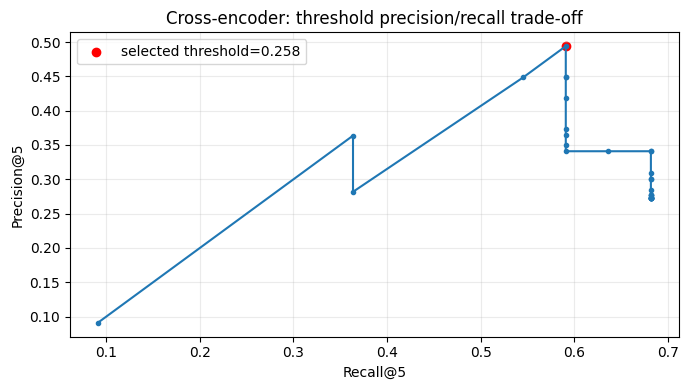

In [ ]:
CROSS_ENCODER_NAME = "cross-encoder/mmarco-mMiniLMv2-L12-H384-v1"
cross_encoder = CrossEncoder(
    CROSS_ENCODER_NAME,
    device=DEVICE,
    max_length=512,
)

DENSE_POOL100 = rankings_for_family(validation_gold, "dense", limit=100)
HYBRID_POOL100 = rankings_for_family(validation_gold, "hybrid", limit=100)


def passage_text(parent_id):
    parent = parent_by_id[parent_id]
    return f"{parent.get('title', '')}\n{parent['text']}"


def candidate_recall(records, rankings, pool_size):
    values = []
    for row in records:
        if row["type"] == "negative":
            continue
        ids = rankings[row["candidate_id"]][0][:pool_size]
        evidence_sets = RELEVANCE.get(row["candidate_id"], [])
        covered = {
            i for i, relevant in enumerate(evidence_sets)
            if any(parent_id in relevant for parent_id in ids)
        }
        values.append(len(covered) / len(evidence_sets) if evidence_sets else 0.0)
    return float(np.mean(values))


def cross_rerank_all(records, source_rankings, pool_size):
    output, latency_rows = {}, []
    for row in records:
        qid = row["candidate_id"]
        candidate_ids = source_rankings[qid][0][:pool_size]
        pairs = [(row["question"], passage_text(pid)) for pid in candidate_ids]
        sync_accelerator()
        started = time.perf_counter_ns()
        scores = np.asarray(
            cross_encoder.predict(pairs, batch_size=32, show_progress_bar=False),
            dtype=np.float32,
        ).reshape(-1)
        sync_accelerator()
        elapsed = (time.perf_counter_ns() - started) / 1e6
        order = np.argsort(-scores, kind="stable")
        output[qid] = (
            [candidate_ids[int(i)] for i in order],
            [float(scores[int(i)]) for i in order],
        )
        latency_rows.append(elapsed)
    return output, latency_rows


def filter_rankings_by_threshold(rankings, threshold):
    filtered = {}
    for qid, (ids, scores) in rankings.items():
        kept = [(pid, score) for pid, score in zip(ids, scores) if score >= threshold]
        filtered[qid] = ([x[0] for x in kept], [float(x[1]) for x in kept])
    return filtered


def threshold_sweep(configuration, raw_rankings, records):
    all_scores = np.asarray(
        [score for _ids, scores in raw_rankings.values() for score in scores],
        dtype=np.float32,
    )
    quantiles = np.linspace(0.0, 1.0, 31)
    thresholds = sorted(set([-math.inf, *np.quantile(all_scores, quantiles).tolist(), math.inf]))
    rows = []
    for threshold in thresholds:
        filtered = filter_rankings_by_threshold(raw_rankings, threshold)
        metrics, _per_query, _by_type = evaluate_rankings(configuration, filtered, records)
        # Для графика threshold trade-off denominator precision — реально
        # возвращённые элементы (до 5), а не фиксированное k. Основные P@5/R@5
        # ниже по-прежнему считаются единообразно с КТ 3.
        set_precisions, set_recalls = [], []
        for row in records:
            if row["type"] == "negative":
                continue
            ids = filtered[row["candidate_id"]][0][:5]
            evidence_sets = RELEVANCE.get(row["candidate_id"], [])
            relevant_union = set().union(*evidence_sets) if evidence_sets else set()
            set_precisions.append(
                sum(parent_id in relevant_union for parent_id in ids) / len(ids)
                if ids else 0.0
            )
            covered = {
                i for i, relevant in enumerate(evidence_sets)
                if any(parent_id in relevant for parent_id in ids)
            }
            set_recalls.append(len(covered) / len(evidence_sets) if evidence_sets else 0.0)
        precision = float(np.mean(set_precisions))
        recall = float(np.mean(set_recalls))
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        rows.append({
            "threshold": threshold,
            "ThresholdPrecision@5": precision,
            "ThresholdRecall@5": recall,
            "ThresholdF1@5": f1,
            **metrics,
        })
    table = pd.DataFrame(rows)
    best = table.sort_values(
        ["ThresholdF1@5", "NDCG@5", "Recall@5"], ascending=False
    ).iloc[0]
    return float(best["threshold"]), table


CROSS_ARTIFACTS = {}
cross_rows = []
cross_threshold_tables = []
cross_type_tables = []
for source_name, source_rankings in [("dense", DENSE_POOL100), ("hybrid", HYBRID_POOL100)]:
    for pool_size in (20, 50, 100):
        config_name = f"cross|{source_name}|pool={pool_size}"
        print(config_name)
        raw_rankings, scoring_ms = cross_rerank_all(
            validation_gold, source_rankings, pool_size
        )
        threshold, threshold_table = threshold_sweep(
            config_name, raw_rankings, validation_gold
        )
        filtered = filter_rankings_by_threshold(raw_rankings, threshold)
        metrics, per_query, by_type = evaluate_rankings(
            config_name, filtered, validation_gold
        )
        cross_rows.append({
            **metrics,
            "source": source_name,
            "pool_size": pool_size,
            "candidate_recall": candidate_recall(validation_gold, source_rankings, pool_size),
            "threshold": threshold,
            "cross_median_ms": float(np.median(scoring_ms)),
            "cross_p95_ms": float(np.percentile(scoring_ms, 95)),
        })
        cross_threshold_tables.append(
            threshold_table.assign(
                source=source_name, pool_size=pool_size, configuration=config_name
            )
        )
        cross_type_tables.append(
            by_type.assign(
                source=source_name, pool_size=pool_size, configuration=config_name
            )
        )
        CROSS_ARTIFACTS[config_name] = {
            "source": source_name, "pool_size": pool_size,
            "raw_rankings": raw_rankings, "rankings": filtered,
            "threshold": threshold, "threshold_table": threshold_table,
            "per_query": per_query, "by_type": by_type,
        }

cross_grid = pd.DataFrame(cross_rows).sort_values(
    ["NDCG@5", "Recall@5", "cross_median_ms"], ascending=[False, False, True]
).reset_index(drop=True)
display(cross_grid[[
    "configuration", "source", "pool_size", "candidate_recall", "threshold",
    "Precision@5", "Recall@5", "NDCG@5", "cross_median_ms", "cross_p95_ms",
]])
cross_grid.to_csv(OUT / "cross_encoder_grid_validation.csv", index=False)
cross_thresholds = pd.concat(cross_threshold_tables, ignore_index=True)
cross_by_type_all = pd.concat(cross_type_tables, ignore_index=True)
cross_thresholds.to_csv(OUT / "cross_encoder_threshold_sweeps.csv", index=False)
cross_by_type_all.to_csv(OUT / "cross_encoder_by_question_type.csv", index=False)
display(cross_by_type_all[[
    "configuration", "source", "pool_size", "type", "n",
    "Precision@5", "Recall@5", "NDCG@5", "NegativeAccuracy",
]].sort_values(["type", "source", "pool_size"]))

BEST_CROSS_NAME = str(cross_grid.iloc[0]["configuration"])
BEST_CROSS = CROSS_ARTIFACTS[BEST_CROSS_NAME]

best_threshold_table = BEST_CROSS["threshold_table"]
finite_thresholds = best_threshold_table[np.isfinite(best_threshold_table["threshold"])]
selected_threshold_row = best_threshold_table.loc[
    best_threshold_table["threshold"] == BEST_CROSS["threshold"]
].iloc[0]
plt.figure(figsize=(7, 4))
plt.plot(
    finite_thresholds["ThresholdRecall@5"],
    finite_thresholds["ThresholdPrecision@5"],
    marker="o", ms=3,
)
plt.scatter(
    [selected_threshold_row["ThresholdRecall@5"]],
    [selected_threshold_row["ThresholdPrecision@5"]],
    color="red", label=f"selected threshold={BEST_CROSS['threshold']:.3f}",
)
plt.xlabel("Recall@5")
plt.ylabel("Precision@5")
plt.title("Cross-encoder: threshold precision/recall trade-off")
plt.legend()
plt.grid(alpha=.25)
plt.tight_layout()
plt.savefig(OUT / "cross_encoder_threshold_tradeoff.png", dpi=160)
plt.show()



## 7. Listwise LLM-as-reranker

Используется listwise, а не pointwise: один вызов модели ранжирует весь пул,
поэтому число LLM-вызовов и служебных токенов существенно меньше. Parent-текст
обрезается до 1200 символов, иначе 20 полных parent-чанков могут не поместиться
в практический контекст Colab-модели.



In [ ]:
LLM_POOL_SIZES = (5, 10, 20)

LLM_RERANK_SYSTEM_V1 = (
    "Ты ранжируешь фрагменты для RAG. Верни только JSON-массив идентификаторов "
    "от самого релевантного к наименее релевантному."
)
LLM_RERANK_SYSTEM_V2 = (
    "Ты детерминированный reranker для RAG. Оцени прямую доказательную полезность "
    "каждого фрагмента для вопроса. При равенстве сохраняй исходный порядок. "
    "Не отвечай на вопрос. Верни только JSON-массив всех ID без пояснений."
)


LLM_PROMPT_TOKEN_BUDGET = 2800
LLM_FALLBACK_TOKEN_BUDGET = 1400


def truncate_tokens(text, max_tokens):
    token_ids = generator_tokenizer.encode(
        str(text),
        add_special_tokens=False,
    )[:max_tokens]

    return generator_tokenizer.decode(
        token_ids,
        skip_special_tokens=True,
    ).strip()


def build_listwise_prompt(
    question,
    candidate_ids,
    token_budget=LLM_PROMPT_TOKEN_BUDGET,
):
    labels = [f"D{i}" for i in range(len(candidate_ids))]

    # Оставляем около 500 токенов для вопроса, инструкций и chat template.
    per_chunk_budget = max(
        40,
        min(320, (token_budget - 500) // max(len(candidate_ids), 1)),
    )

    blocks = []

    for i, parent_id in enumerate(candidate_ids):
        parent = parent_by_id[parent_id]

        raw_text = (
            f"[D{i}] Заголовок: {parent.get('title', '')}\n"
            f"Текст: {re.sub(r'\\s+', ' ', parent['text']).strip()}"
        )

        blocks.append(
            truncate_tokens(raw_text, per_chunk_budget)
        )

    prompt = (
        f"Вопрос: {question}\n\n"
        "Расположи ВСЕ ID по убыванию релевантности вопросу. "
        "Точный ответ и прямые свидетельства важнее тематического сходства.\n\n"
        + "\n\n".join(blocks)
        + f"\n\nВерни ровно эти ID по одному разу: {json.dumps(labels)}"
    )

    return prompt, labels


def llm_rerank(question, candidate_ids, prompt_version="v2"):
    system = (
        LLM_RERANK_SYSTEM_V2
        if prompt_version == "v2"
        else LLM_RERANK_SYSTEM_V1
    )

    prompt, labels = build_listwise_prompt(
        question,
        candidate_ids,
        token_budget=LLM_PROMPT_TOKEN_BUDGET,
    )

    try:
        raw, usage = chat_generate(
            system,
            prompt,
            max_new_tokens=max(80, 6 * len(labels)),
        )
        usage["oom_retry"] = False

    except torch.cuda.OutOfMemoryError:
        gc.collect()
        torch.cuda.empty_cache()

        print("OOM: повтор с уменьшенным токен-бюджетом")

        prompt, labels = build_listwise_prompt(
            question,
            candidate_ids,
            token_budget=LLM_FALLBACK_TOKEN_BUDGET,
        )

        raw, usage = chat_generate(
            system,
            prompt,
            max_new_tokens=max(80, 6 * len(labels)),
        )
        usage["oom_retry"] = True

    parsed = extract_json_array(raw) or []

    order = []

    for value in parsed:
        label = str(value).strip()

        if label in labels and label not in order:
            order.append(label)

    # Добавляем пропущенные моделью ID в исходном порядке.
    order.extend(label for label in labels if label not in order)

    label_to_parent = {
        f"D{i}": parent_id
        for i, parent_id in enumerate(candidate_ids)
    }

    ranked_ids = [label_to_parent[label] for label in order]
    rank_scores = [
        1.0 / (rank + 1)
        for rank in range(len(ranked_ids))
    ]

    usage["raw_output"] = raw
    usage["parse_complete"] = (
        len(parsed) == len(labels)
        and len(set(map(str, parsed))) == len(labels)
    )

    return (ranked_ids, rank_scores), usage

def llm_rerank_all(records, source_rankings, pool_size, prompt_version="v2"):
    output, usage_rows = {}, []
    for i, row in enumerate(records, 1):
        candidates = source_rankings[row["candidate_id"]][0][:pool_size]
        ranked, usage = llm_rerank(row["question"], candidates, prompt_version)
        output[row["candidate_id"]] = ranked
        usage_rows.append({"candidate_id": row["candidate_id"], **usage})
        print(f"LLM pool={pool_size}: {i}/{len(records)}", end="\r")
    print()
    return output, pd.DataFrame(usage_rows)



### 7.1 Детерминированность

Двадцать одинаковых query+pool прогоняются дважды при `do_sample=False`
(эквивалент temperature=0). Сначала тестируется короткий prompt v1. Если exact
agreement ниже 90%, автоматически включается более строгий v2 и тест повторяется.



In [ ]:
def determinism_test(prompt_version, n=20, pool_size=10):
    records = validation_gold[:min(n, len(validation_gold))]
    rows = []
    for i, row in enumerate(records, 1):
        candidates = BASELINE_RANKINGS[row["candidate_id"]][0][:pool_size]
        first, usage_1 = llm_rerank(row["question"], candidates, prompt_version)
        second, usage_2 = llm_rerank(row["question"], candidates, prompt_version)
        rows.append({
            "candidate_id": row["candidate_id"],
            "prompt_version": prompt_version,
            "exact_agreement": first[0] == second[0],
            "first_order": json.dumps(first[0]),
            "second_order": json.dumps(second[0]),
            "tokens_run_1": usage_1["input_tokens"] + usage_1["output_tokens"],
            "tokens_run_2": usage_2["input_tokens"] + usage_2["output_tokens"],
        })
        print(f"Determinism {prompt_version}: {i}/{len(records)}", end="\r")
    print()
    table = pd.DataFrame(rows)
    return float(table["exact_agreement"].mean()), table


agreement_v1, determinism_v1 = determinism_test("v1")
if agreement_v1 < 0.90:
    agreement_final, determinism_final = determinism_test("v2")
    selected_prompt_version = "v2"
else:
    agreement_final, determinism_final = agreement_v1, determinism_v1
    selected_prompt_version = "v1"

determinism_table = pd.concat(
    [determinism_v1] + ([] if selected_prompt_version == "v1" else [determinism_final]),
    ignore_index=True,
)
determinism_table.to_csv(OUT / "llm_reranker_determinism.csv", index=False)
print(f"Agreement v1={agreement_v1:.1%}; selected={selected_prompt_version}; final={agreement_final:.1%}")
if agreement_final < 0.90:
    warnings.warn("Agreement ниже 90%: LLM-reranker нельзя рекомендовать без дополнительной доработки.")



The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Determinism v1: 17/17
Agreement v1=100.0%; selected=v1; final=100.0%


### 7.2 Размер candidate pool: 5 / 10 / 20



In [ ]:
LLM_ARTIFACTS = {}
llm_rows = []
for pool_size in LLM_POOL_SIZES:
    name = f"llm_listwise|pool={pool_size}|prompt={selected_prompt_version}"
    rankings, usage_df = llm_rerank_all(
        validation_gold, BASELINE_RANKINGS, pool_size, selected_prompt_version
    )
    metrics, per_query, by_type = evaluate_rankings(name, rankings, validation_gold)
    llm_rows.append({
        **metrics,
        "pool_size": pool_size,
        "llm_median_ms": float(usage_df["latency_ms"].median()),
        "llm_p95_ms": float(usage_df["latency_ms"].quantile(.95)),
        "tokens_per_query": float(
            (usage_df["input_tokens"] + usage_df["output_tokens"]).mean()
        ),
        "parse_complete_rate": float(usage_df["parse_complete"].mean()),
    })
    LLM_ARTIFACTS[name] = {
        "pool_size": pool_size, "rankings": rankings,
        "usage": usage_df, "per_query": per_query, "by_type": by_type,
    }

llm_grid = pd.DataFrame(llm_rows).sort_values(
    ["NDCG@5", "Recall@5", "llm_median_ms"], ascending=[False, False, True]
).reset_index(drop=True)
display(llm_grid[[
    "configuration", "pool_size", "Precision@5", "Recall@5", "NDCG@5",
    "llm_median_ms", "llm_p95_ms", "tokens_per_query", "parse_complete_rate",
]])
llm_grid.to_csv(OUT / "llm_reranker_pool_validation.csv", index=False)

BEST_LLM_NAME = str(llm_grid.iloc[0]["configuration"])
BEST_LLM = LLM_ARTIFACTS[BEST_LLM_NAME]



The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


LLM pool=20: 17/17


,configuration,pool_size,Precision@5,Recall@5,NDCG@5,llm_median_ms,llm_p95_ms,tokens_per_query,parse_complete_rate
0,llm_listwise|pool=10|prompt=v1,10,0.181818,0.636364,0.642340,3423.020794,3484.942791,2521.411765,1.000000
1,llm_listwise|pool=20|prompt=v1,20,0.181818,0.636364,0.638475,6165.902494,7661.321127,2645.117647,0.941176
2,llm_listwise|pool=5|prompt=v1,5,0.181818,0.636364,0.636033,1843.387121,1891.494380,1759.294118,1.000000


## 8. Комбинации: transformation + reranker

Cross-encoder получает top-N от multi-query RRF и применяет порог, выбранный
раньше. LLM получает top-N от multi-query и использует уже выбранные pool и
prompt. Нового подбора параметров здесь нет.



In [ ]:
def cross_rerank_given_source(records, source_rankings, pool_size, threshold):
    raw, _times = cross_rerank_all(records, source_rankings, pool_size)
    return filter_rankings_by_threshold(raw, threshold)


TRANSFORM_CROSS_RANKINGS = cross_rerank_given_source(
    validation_gold,
    MULTI_QUERY_RANKINGS,
    BEST_CROSS["pool_size"],
    BEST_CROSS["threshold"],
)
transform_cross_metrics, transform_cross_per_query, transform_cross_by_type = evaluate_rankings(
    "+ multi-query + cross-encoder", TRANSFORM_CROSS_RANKINGS, validation_gold
)

TRANSFORM_LLM_RANKINGS, transform_llm_usage = llm_rerank_all(
    validation_gold,
    MULTI_QUERY_RANKINGS,
    BEST_LLM["pool_size"],
    selected_prompt_version,
)
transform_llm_metrics, transform_llm_per_query, transform_llm_by_type = evaluate_rankings(
    "+ multi-query + LLM-reranker", TRANSFORM_LLM_RANKINGS, validation_gold
)



The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


LLM pool=10: 17/17


## 9. Полный latency profile по этапам — 100 запросов

Это самая долгая ячейка. Она делает реальные вызовы, а не подставляет время из
кэша. Результаты сохраняются после каждого запроса, поэтому ячейку можно
перезапустить после разрыва сессии. `total_ms` измеряется end-to-end; этапы
дополнительно показывают bottleneck. Токены — input+output локальной LLM.



In [ ]:
FINAL_CONFIGS = [
    "baseline",
    "transform",
    "cross",
    "llm",
    "transform_cross",
    "transform_llm",
]


def merge_timings(total, addition):
    for key in ("transform_ms", "embed_ms", "search_ms", "cross_ms", "llm_ms"):
        total[key] = total.get(key, 0.0) + addition.get(key, 0.0)


def multi_query_retrieve_profiled(question, family, limit=100):
    timing = {"transform_ms": 0.0, "embed_ms": 0.0, "search_ms": 0.0,
              "cross_ms": 0.0, "llm_ms": 0.0}
    expansions, usage = generate_multi_queries(question, use_cache=False)
    timing["transform_ms"] += usage["latency_ms"]
    results = []
    for query in [question, *expansions]:
        result, part = retrieve_profiled(query, family, limit=limit)
        results.append(result)
        merge_timings(timing, part)
    fusion_started = time.perf_counter_ns()
    fused = fuse_rrf(*results, rrf_k=RRF_K)
    timing["search_ms"] += (time.perf_counter_ns() - fusion_started) / 1e6
    tokens = usage["input_tokens"] + usage["output_tokens"]
    return (fused[0][:limit], fused[1][:limit]), timing, tokens


def cross_rerank_live(question, source_result, pool_size, threshold):
    candidates = source_result[0][:pool_size]
    pairs = [(question, passage_text(pid)) for pid in candidates]
    sync_accelerator()
    started = time.perf_counter_ns()
    scores = np.asarray(
        cross_encoder.predict(pairs, batch_size=32, show_progress_bar=False),
        dtype=np.float32,
    ).reshape(-1)
    sync_accelerator()
    elapsed = (time.perf_counter_ns() - started) / 1e6
    order = np.argsort(-scores, kind="stable")
    ids = [candidates[int(i)] for i in order if float(scores[int(i)]) >= threshold]
    ranked_scores = [float(scores[int(i)]) for i in order if float(scores[int(i)]) >= threshold]
    return (ids, ranked_scores), elapsed


def run_live_configuration(question, config):
    end_to_end_started = time.perf_counter_ns()
    timing = {"transform_ms": 0.0, "embed_ms": 0.0, "search_ms": 0.0,
              "cross_ms": 0.0, "llm_ms": 0.0}
    tokens = 0

    if config in {"transform", "transform_cross", "transform_llm"}:
        source, part, transform_tokens = multi_query_retrieve_profiled(
            question, BASELINE_FAMILY, limit=100
        )
        merge_timings(timing, part)
        tokens += transform_tokens
    elif config == "cross":
        source, part = retrieve_profiled(question, BEST_CROSS["source"], limit=100)
        merge_timings(timing, part)
    else:
        source, part = retrieve_profiled(question, BASELINE_FAMILY, limit=100)
        merge_timings(timing, part)

    if config in {"cross", "transform_cross"}:
        result, elapsed = cross_rerank_live(
            question, source, BEST_CROSS["pool_size"], BEST_CROSS["threshold"]
        )
        timing["cross_ms"] += elapsed
    elif config in {"llm", "transform_llm"}:
        candidates = source[0][:BEST_LLM["pool_size"]]
        result, usage = llm_rerank(question, candidates, selected_prompt_version)
        timing["llm_ms"] += usage["latency_ms"]
        tokens += usage["input_tokens"] + usage["output_tokens"]
    else:
        result = source

    sync_accelerator()
    timing["total_ms"] = (time.perf_counter_ns() - end_to_end_started) / 1e6
    timing["tokens"] = tokens
    return result, timing


LATENCY_RAW_PATH = OUT / "latency_profile_raw.csv"
if LATENCY_RAW_PATH.exists():
    latency_raw = pd.read_csv(LATENCY_RAW_PATH)
else:
    latency_raw = pd.DataFrame()

questions = [row["question"] for row in validation_gold]
new_latency_rows = []
for config in FINAL_CONFIGS:
    existing = set()
    if not latency_raw.empty:
        existing = set(
            latency_raw.loc[latency_raw["configuration"] == config, "sample"].astype(int)
        )
    for sample in range(LATENCY_REPEATS):
        if sample in existing:
            continue
        question = questions[sample % len(questions)]
        _result, timing = run_live_configuration(question, config)
        new_latency_rows.append({"configuration": config, "sample": sample, **timing})
        combined = pd.concat([latency_raw, pd.DataFrame(new_latency_rows)], ignore_index=True)
        combined.to_csv(LATENCY_RAW_PATH, index=False)
        print(f"Latency {config}: {sample + 1}/{LATENCY_REPEATS}", end="\r")
    print()
    if new_latency_rows:
        latency_raw = pd.concat([latency_raw, pd.DataFrame(new_latency_rows)], ignore_index=True)
        new_latency_rows = []


def latency_summary_for(config):
    part = latency_raw[latency_raw["configuration"] == config]
    stage_medians = {
        stage: float(part[stage].median())
        for stage in ("transform_ms", "embed_ms", "search_ms", "cross_ms", "llm_ms")
    }
    return {
        "configuration_key": config,
        "median_latency_ms": float(part["total_ms"].median()),
        "p95_latency_ms": float(part["total_ms"].quantile(.95)),
        "tokens_per_query": float(part["tokens"].mean()),
        "bottleneck": max(stage_medians, key=stage_medians.get),
        **{f"median_{key}": value for key, value in stage_medians.items()},
    }


latency_summary = pd.DataFrame([latency_summary_for(config) for config in FINAL_CONFIGS])
display(latency_summary)
latency_summary.to_csv(OUT / "latency_profile_summary.csv", index=False)



The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Latency baseline: 100/100


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Latency transform_llm: 100/100
Latency transform_llm: 100/100


,configuration_key,median_latency_ms,p95_latency_ms,tokens_per_query,bottleneck,median_transform_ms,median_embed_ms,median_search_ms,median_cross_ms,median_llm_ms
0,baseline,481.530158,537.641627,0.00,search_ms,0.000000,26.229017,451.413099,0.000000,0.000000
1,transform,5725.929697,8990.792301,282.73,transform_ms,3957.632289,94.460065,1810.528980,0.000000,0.000000
2,cross,720.117469,781.241826,0.00,search_ms,0.000000,24.238360,440.337394,252.976056,0.000000
3,llm,3891.059309,4015.991634,2521.23,llm_ms,0.000000,23.985932,448.239690,0.000000,3385.457447
4,transform_cross,5974.390688,9233.988413,282.73,transform_ms,3852.446780,93.229456,1804.049403,314.173874,0.000000
5,transform_llm,9130.840690,12295.321386,2797.01,transform_ms,3880.162621,93.947565,1790.375931,0.000000,3428.554637


,configuration_key,median_latency_ms,p95_latency_ms,tokens_per_query,bottleneck,median_transform_ms,median_embed_ms,median_search_ms,median_cross_ms,median_llm_ms
0,baseline,481.530158,537.641627,0.00,search_ms,0.000000,26.229017,451.413099,0.000000,0.000000
1,transform,5725.929697,8990.792301,282.73,transform_ms,3957.632289,94.460065,1810.528980,0.000000,0.000000
2,cross,720.117469,781.241826,0.00,search_ms,0.000000,24.238360,440.337394,252.976056,0.000000
3,llm,3891.059309,4015.991634,2521.23,llm_ms,0.000000,23.985932,448.239690,0.000000,3385.457447
4,transform_cross,5974.390688,9233.988413,282.73,transform_ms,3852.446780,93.229456,1804.049403,314.173874,0.000000
5,transform_llm,9130.840690,12295.321386,2797.01,transform_ms,3880.162621,93.947565,1790.375931,0.000000,3428.554637


## 10. Итоговая таблица и график latency–Recall



,configuration_key,configuration,Precision@5,Recall@5,NDCG@5,MAP,MRR,delta_Recall@5_vs_baseline,delta_NDCG@5_vs_baseline,median_latency_ms,p95_latency_ms,tokens_per_query,bottleneck,median_transform_ms,median_embed_ms,median_search_ms,median_cross_ms,median_llm_ms
0,baseline,baseline (KT3),0.182,0.636,0.638,0.616,0.744,+0.000,+0.000,481.5,537.6,0,search_ms,0.000000,26.229017,451.413099,0.000000,0.000000
1,transform,+ multi-query,0.182,0.636,0.646,0.614,0.774,+0.000,+0.007,5725.9,8990.8,283,transform_ms,3957.632289,94.460065,1810.528980,0.000000,0.000000
2,cross,+ cross-encoder,0.164,0.591,0.594,0.576,0.636,-0.045,-0.045,720.1,781.2,0,search_ms,0.000000,24.238360,440.337394,252.976056,0.000000
3,llm,+ LLM-reranker,0.182,0.636,0.642,0.614,0.742,+0.000,+0.004,3891.1,4016.0,2521,llm_ms,0.000000,23.985932,448.239690,0.000000,3385.457447
4,transform_cross,+ multi-query + cross-encoder,0.145,0.545,0.566,0.545,0.636,-0.091,-0.072,5974.4,9234.0,283,transform_ms,3852.446780,93.229456,1804.049403,314.173874,0.000000
5,transform_llm,+ multi-query + LLM-reranker,0.182,0.636,0.646,0.606,0.773,+0.000,+0.007,9130.8,12295.3,2797,transform_ms,3880.162621,93.947565,1790.375931,0.000000,3428.554637


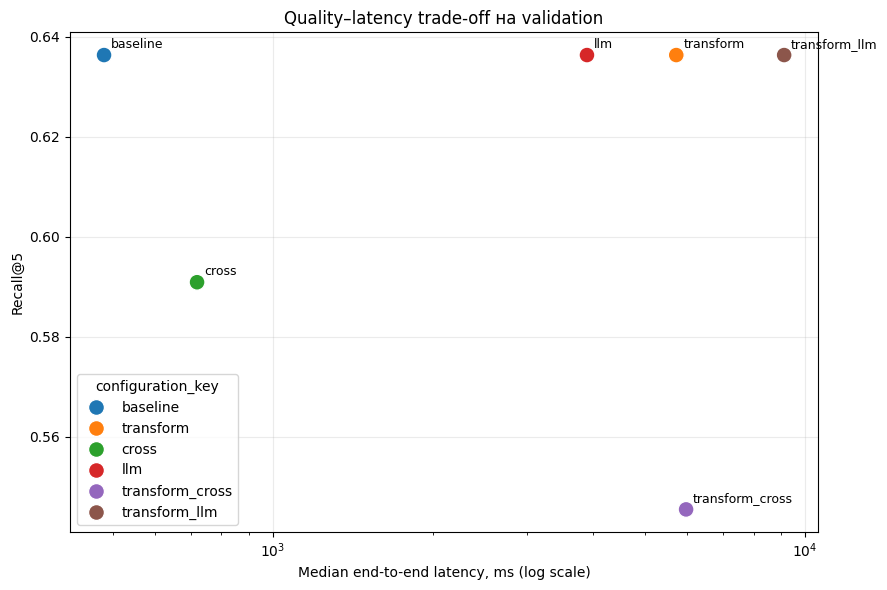

In [ ]:
BEST_CROSS_METRICS, _, BEST_CROSS_BY_TYPE = evaluate_rankings(
    "+ cross-encoder", BEST_CROSS["rankings"], validation_gold
)
BEST_LLM_METRICS, _, BEST_LLM_BY_TYPE = evaluate_rankings(
    "+ LLM-reranker", BEST_LLM["rankings"], validation_gold
)

metric_rows = [
    {**baseline_metrics, "configuration_key": "baseline"},
    {**multi_metrics, "configuration_key": "transform"},
    {**BEST_CROSS_METRICS, "configuration_key": "cross"},
    {**BEST_LLM_METRICS, "configuration_key": "llm"},
    {**transform_cross_metrics, "configuration_key": "transform_cross"},
    {**transform_llm_metrics, "configuration_key": "transform_llm"},
]
final_table = pd.DataFrame(metric_rows).merge(latency_summary, on="configuration_key")
final_table["delta_Recall@5_vs_baseline"] = final_table["Recall@5"] - baseline_metrics["Recall@5"]
final_table["delta_NDCG@5_vs_baseline"] = final_table["NDCG@5"] - baseline_metrics["NDCG@5"]
final_table = final_table[[
    "configuration_key", "configuration",
    "Precision@5", "Recall@5", "NDCG@5", "MAP", "MRR",
    "delta_Recall@5_vs_baseline", "delta_NDCG@5_vs_baseline",
    "median_latency_ms", "p95_latency_ms", "tokens_per_query", "bottleneck",
    "median_transform_ms", "median_embed_ms", "median_search_ms",
    "median_cross_ms", "median_llm_ms",
]]
display(final_table.style.format({
    "Precision@5": "{:.3f}", "Recall@5": "{:.3f}", "NDCG@5": "{:.3f}",
    "MAP": "{:.3f}", "MRR": "{:.3f}",
    "delta_Recall@5_vs_baseline": "{:+.3f}",
    "delta_NDCG@5_vs_baseline": "{:+.3f}",
    "median_latency_ms": "{:.1f}", "p95_latency_ms": "{:.1f}",
    "tokens_per_query": "{:.0f}",
}))
final_table.to_csv(OUT / "kt4_final_comparison_validation.csv", index=False)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=final_table,
    x="median_latency_ms", y="Recall@5",
    hue="configuration_key", s=130,
)
for _, row in final_table.iterrows():
    plt.annotate(
        row["configuration_key"],
        (row["median_latency_ms"], row["Recall@5"]),
        xytext=(5, 5), textcoords="offset points", fontsize=9,
    )
plt.title("Quality–latency trade-off на validation")
plt.xlabel("Median end-to-end latency, ms (log scale)")
plt.ylabel("Recall@5")
plt.xscale("log")
plt.grid(alpha=.25)
plt.tight_layout()
plt.savefig(OUT / "latency_vs_recall_validation.png", dpi=180)
plt.show()



### 11. Сохранение артефактов



In [ ]:
experiment_summary = {
    "baseline_from_kt3": KT3_RECOMMENDATION,
    "query_transformation": {
        "method": "Multi-query expansion",
        "queries": 3,
        "fusion": f"RRF(k={RRF_K})",
        "model": GENERATOR_MODEL_NAME,
        "delta_recall_at_5": multi_metrics["Recall@5"] - baseline_metrics["Recall@5"],
        "delta_ndcg_at_5": multi_metrics["NDCG@5"] - baseline_metrics["NDCG@5"],
    },
    "cross_encoder": {
        "model": CROSS_ENCODER_NAME,
        "selected": BEST_CROSS_NAME,
        "pool": BEST_CROSS["pool_size"],
        "threshold": BEST_CROSS["threshold"],
    },
    "llm_reranker": {
        "model": GENERATOR_MODEL_NAME,
        "method": "listwise",
        "selected": BEST_LLM_NAME,
        "pool": BEST_LLM["pool_size"],
        "prompt_version": selected_prompt_version,
        "agreement_rate": agreement_final,
    },
    "latency_repetitions": LATENCY_REPEATS,
}
(OUT / "kt4_experiment_summary.json").write_text(
    json.dumps(experiment_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)


1329